**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
By: TAP

### Install Librarynya

In [13]:
!pip install numpy matplotlib

## Load Data, Normalisasi, dan Contoh Gambar

Dataset yang dipakai adalah MNIST, yaitu gambar digit tulisan tangan 0-9 berukuran 28x28 piksel (grayscale). Terdapat 60.000 data training dan 10.000 data test.

- `mnist.load_data()` memuat dataset dan membaginya menjadi data training dan data test.
- Normalisasi dengan `/ 255.0` mengubah nilai piksel dari rentang 0-255 menjadi 0-1 agar training lebih stabil dan cepat.
- `class_names` berisi label untuk tiap kelas (angka 0-9).
- Loop menampilkan 25 gambar pertama beserta labelnya untuk memastikan data terbaca dengan benar.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 431s 37us/step


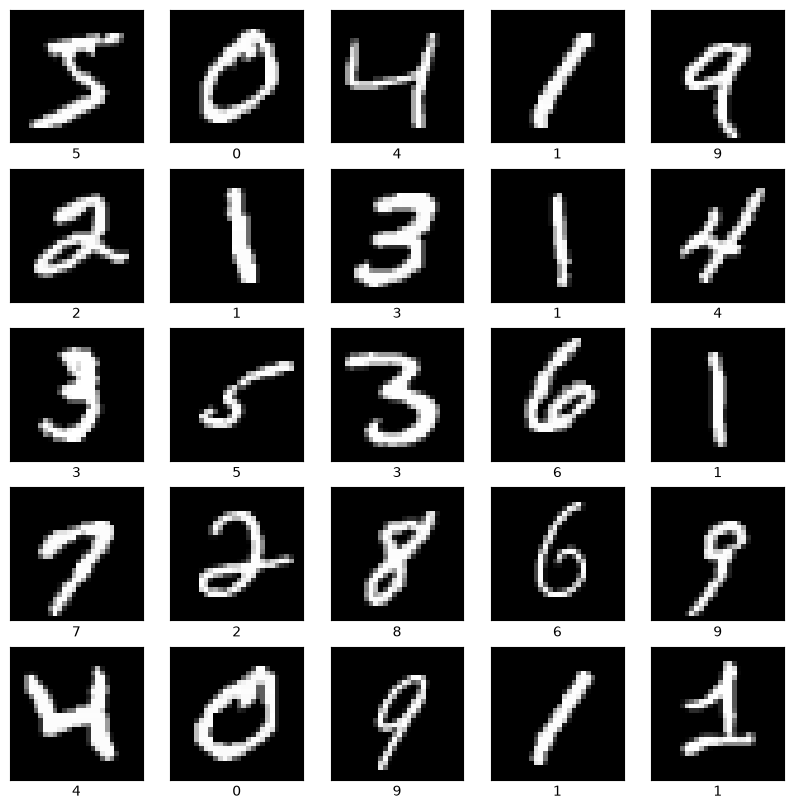

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images / 255.0
test_images = test_images / 255.0

class_names = [str(i) for i in range(10)]

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(class_names[train_labels[i]])
plt.show()

## Membangun Model Neural Network

Model dibuat dengan `Sequential`, yaitu layer yang disusun berurutan:

- `Flatten(input_shape=(28, 28))` mengubah gambar 2D (28x28) menjadi vektor 1D dengan 784 nilai.
- `Dense(128, activation='relu')` adalah hidden layer dengan 128 neuron. Fungsi aktivasi ReLU mengubah nilai negatif menjadi 0 sehingga model dapat mempelajari pola non-linear.
- `Dense(10, activation='softmax')` adalah output layer dengan 10 neuron (satu untuk tiap digit). Softmax mengubah output menjadi probabilitas dengan jumlah total 1.
- `model.summary()` menampilkan arsitektur model dan jumlah parameter yang dipelajari.

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])
model.summary()

c:\Users\WIN11\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Compile dan Training Model

- `optimizer='adam'` adalah algoritma yang memperbarui bobot model agar error semakin kecil.
- `loss='sparse_categorical_crossentropy'` adalah fungsi untuk mengukur kesalahan prediksi pada klasifikasi multi-kelas dengan label berupa angka bulat.
- `metrics=['accuracy']` digunakan untuk memantau akurasi selama training.
- `model.fit(..., epochs=10)` melatih model sebanyak 10 epoch pada seluruh data training. `validation_data` digunakan untuk mengecek performa model pada data test di setiap epoch.
- Hasil training disimpan di `history` untuk dibuat grafik.

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.9266 - loss: 0.2557 - val_accuracy: 0.9580 - val_loss: 0.1391
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9662 - loss: 0.1147 - val_accuracy: 0.9698 - val_loss: 0.0984
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9765 - loss: 0.0784 - val_accuracy: 0.9734 - val_loss: 0.0859
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9829 - loss: 0.0579 - val_accuracy: 0.9753 - val_loss: 0.0823
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9878 - loss: 0.0429 - val_accuracy: 0.9747 - val_loss: 0.0817
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9911 - loss: 0.0322 - val_accuracy: 0.9763 - val_loss: 0.0838
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9937 - loss: 0.0244 - val_accuracy: 0.9757 - val_loss: 0.0872
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9951 - loss: 0.0

## Evaluasi Model

`model.evaluate()` menguji model yang sudah dilatih pada data test dan menghasilkan nilai loss dan akurasi akhir. Nilai `test_acc` menunjukkan persentase gambar test yang berhasil diprediksi dengan benar.

In [ ]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'\nTest accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9778 - loss: 0.0932

Test accuracy: 0.9778000116348267


## Grafik Akurasi dan Loss

Fungsi `plot_history` membuat dua grafik dari `history`:

- Grafik akurasi training dan validation per epoch.
- Grafik loss training dan validation per epoch.

Jika akurasi training terus naik sementara akurasi validation mendatar atau turun (dan loss validation naik), model mengalami overfitting. Jika keduanya naik dan berdekatan, model belajar dengan baik.

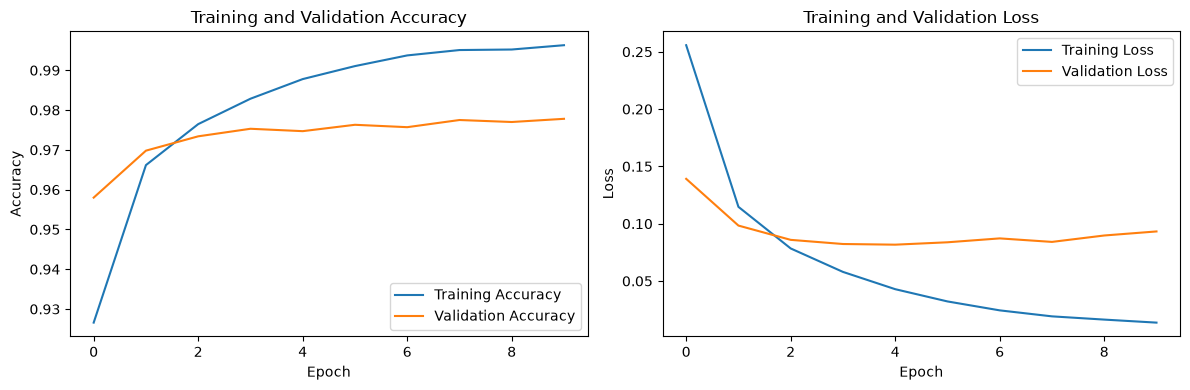

In [ ]:
def plot_history(history):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(loc='lower right')

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

plot_history(history)

## Prediksi pada Data Test

- `model.predict(test_images)` menghasilkan 10 nilai probabilitas untuk tiap gambar.
- `np.argmax(predictions[i])` mengambil kelas dengan probabilitas tertinggi sebagai hasil prediksi.
- Loop menampilkan 25 gambar test pertama beserta label prediksi dan label asli, sehingga terlihat gambar mana yang diprediksi benar atau salah.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


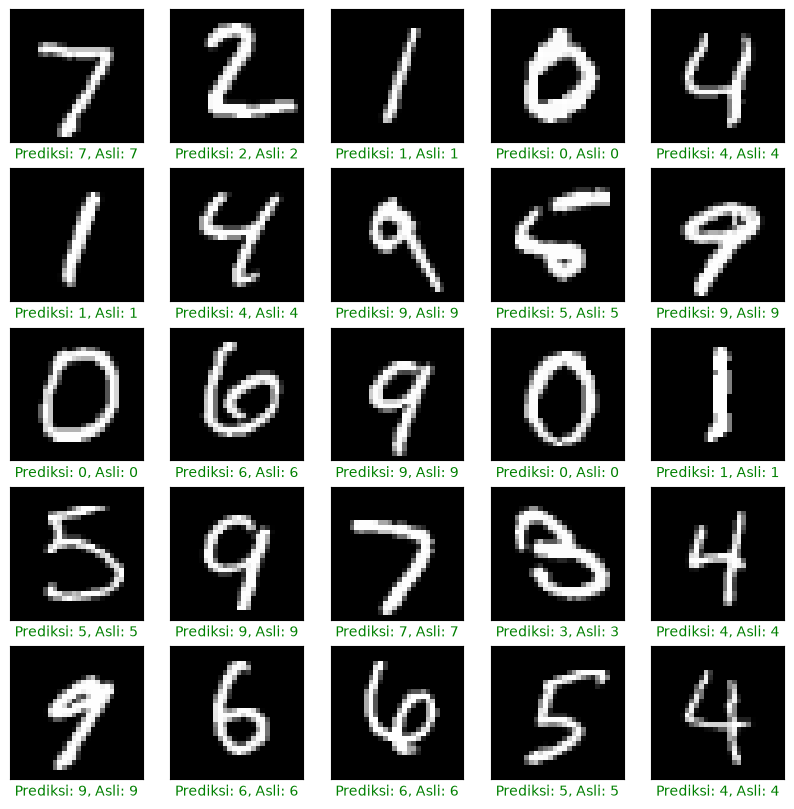

In [ ]:
predictions = model.predict(test_images)

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    pred = np.argmax(predictions[i])
    actual = test_labels[i]
    plt.xlabel(f"Prediksi: {pred}, Asli: {actual}",
               color='green' if pred == actual else 'red')
plt.show()

**Tugas** <br>
Implementasikan kode program di atas dengan dataset yang berbeda serta jelaskan apa yang Anda buat. Tugas dikumpulkan di hari Selasa, 3 Oktober 2026 jam 23.59 WIB di ecourse (baru).

### melihat daftar dataset bawaan yang tersedia di tf.keras.datasets

In [20]:
import tensorflow as tf
print(dir(tf.keras.datasets))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'boston_housing', 'california_housing', 'cifar10', 'cifar100', 'fashion_mnist', 'imdb', 'mnist', 'reuters']
